In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("credit_card_fraud_2026.csv")
df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  str    
 3   card_type                     20000 non-null  str    
 4   auth_method                   20000 non-null  str    
 5   channel                       20000 non-null  str    
 6   device_type                   20000 non-null  str    
 7   is_foreign_transaction        20000 non-null  bool   
 8   hours_since_last_txn          20000 non-null  float64
 9   txn_count_last_24h            20000 non-null  int64  
 10  distance_from_home_km         20000 non-null  float64
 11  card_age_months               20000 non-null  int64  
 12  customer_age                  20000 non-null  int64  
 13  account_bala

In [5]:
df.describe()

,transaction_id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,10000.500000,132.424597,8.950827,3.191650,22.139525,46.937550,49.669400,3316.662598,0.181300,19.807735,11.533650,2.998750,37.400390,0.281250,0.016950
std,5773.647028,256.963666,8.838745,1.779544,22.120960,6.768577,18.494032,4350.720948,0.422302,12.366301,6.925335,2.004956,17.061415,0.529209,0.129087
min,1.000000,1.000000,0.010000,0.000000,0.000000,22.000000,18.000000,52.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5000.750000,26.235000,2.590000,2.000000,6.337500,42.000000,34.000000,1019.140000,0.000000,10.700000,6.000000,1.000000,25.600000,0.000000,0.000000
50%,10000.500000,57.510000,6.210000,3.000000,15.505000,47.000000,50.000000,2007.685000,0.000000,18.800000,12.000000,3.000000,35.700000,0.000000,0.000000
75%,15000.250000,131.752500,12.432500,4.000000,30.820000,51.000000,66.000000,3944.120000,0.000000,27.600000,18.000000,5.000000,47.300000,0.000000,0.000000
max,20000.000000,6872.690000,87.050000,12.000000,216.190000,74.000000,81.000000,127125.860000,3.000000,74.400000,23.000000,6.000000,100.000000,4.000000,1.000000


In [6]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
 transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64
Duplicate rows: 0


C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\1359345058.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_fraud', data=df, palette='Set2')


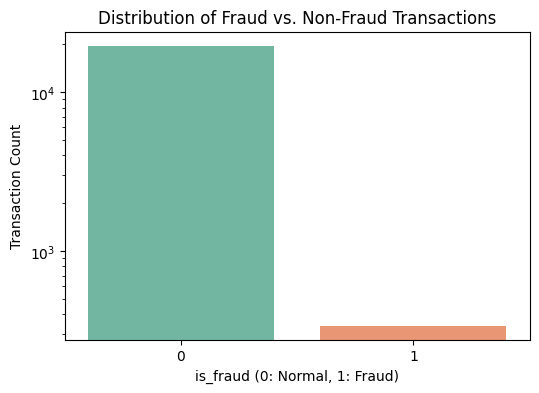

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(x='is_fraud', data=df, palette='Set2')
plt.title('Distribution of Fraud vs. Non-Fraud Transactions')
plt.xlabel('is_fraud (0: Normal, 1: Fraud)')
plt.ylabel('Transaction Count')
# Use log scale if the imbalance is too extreme to view visually
plt.yscale('log')
plt.show()

Fraud rate: 1.70%  (339 of 20000)
Accuracy of a "never fraud" model: 98.30%  <-- catches ZERO fraud


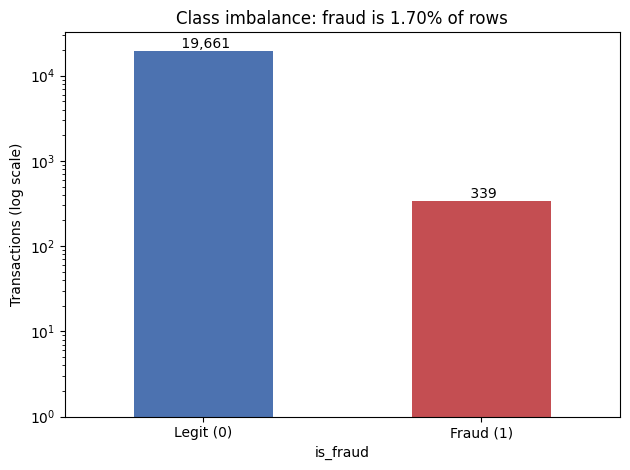

In [8]:
rate = df['is_fraud'].mean()
print(f'Fraud rate: {rate*100:.2f}%  ({df.is_fraud.sum()} of {len(df)})')
print(
    f'Accuracy of a "never fraud" model: {(1-rate)*100:.2f}%  <-- catches ZERO fraud')

counts = df['is_fraud'].value_counts().sort_index()
ax = counts.plot(kind='bar', color=['#4C72B0', '#C44E52'], log=True)
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'], rotation=0)
ax.set_ylabel('Transactions (log scale)')
ax.set_title(f'Class imbalance: fraud is {rate*100:.2f}% of rows')
for i, v in enumerate(counts):
    ax.text(i, v, f' {v:,}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

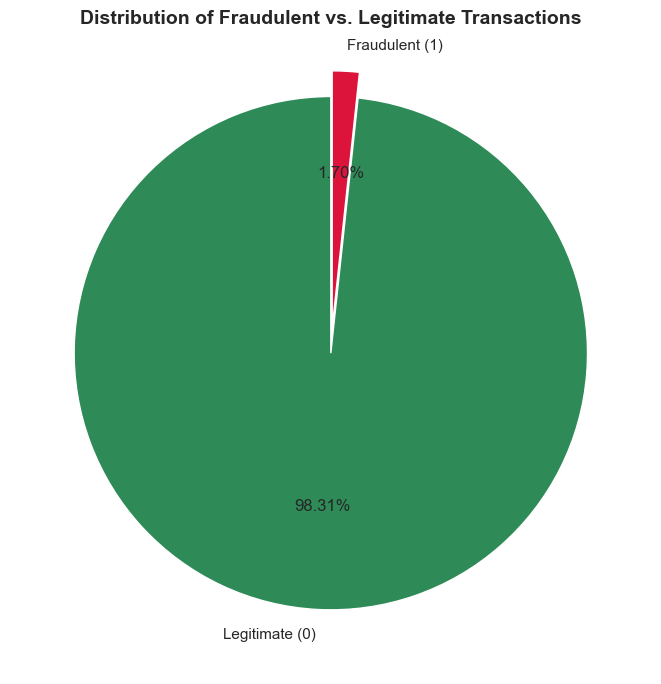

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Check if 'is_fraud' column exists
if "is_fraud" in df.columns:
    # Get value counts of is_fraud
    fraud_counts = df["is_fraud"].value_counts()

    plt.figure(figsize=(7, 7))

    # Plot pie chart with a small 'explode' on the fraud slice to make it visible
    plt.pie(
        fraud_counts,
        labels=["Legitimate (0)", "Fraudulent (1)"],
        colors=["seagreen", "crimson"],
        autopct="%1.2f%%",
        startangle=90,
        explode=(0, 0.1),  # Pulls out the fraud slice slightly for emphasis
    )

    plt.title(
        "Distribution of Fraudulent vs. Legitimate Transactions",
        fontsize=14,
        fontweight="bold",
    )

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Column 'is_fraud' not found in df.")

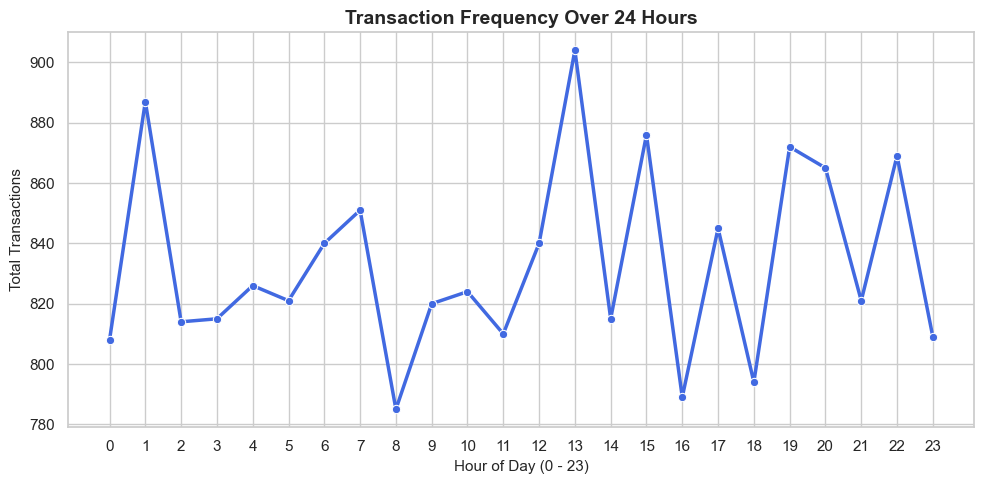

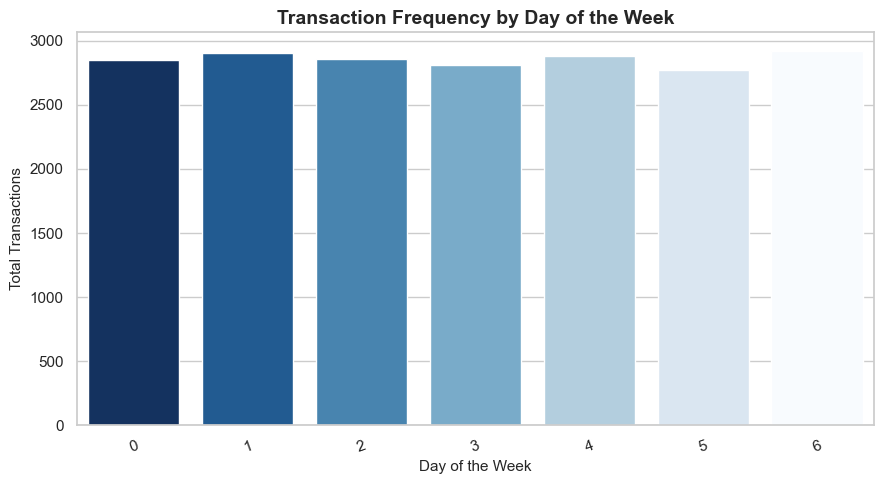

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# --- 1. TRANSACTION FREQUENCY BY HOUR OF THE DAY ---
if "time_of_day_hour" in df.columns:
    plt.figure(figsize=(10, 5))

    # Count transactions per hour and plot as a line/area chart with markers
    hourly_counts = (
        df["time_of_day_hour"].value_counts().sort_index().reset_index()
    )
    hourly_counts.columns = ["hour", "transaction_count"]

    sns.lineplot(
        data=hourly_counts,
        x="hour",
        y="transaction_count",
        marker="o",
        color="royalblue",
        linewidth=2.5,
    )

    plt.title(
        "Transaction Frequency Over 24 Hours", fontsize=14, fontweight="bold"
    )
    plt.xlabel("Hour of Day (0 - 23)", fontsize=11)
    plt.ylabel("Total Transactions", fontsize=11)
    plt.xticks(range(0, 24))

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Column 'time_of_day_hour' not found in df.")


# --- 2. TRANSACTION FREQUENCY BY DAY OF THE WEEK ---
if "day_of_week" in df.columns:
    plt.figure(figsize=(9, 5))

    # Count transactions per day of the week
    daily_counts = df["day_of_week"].value_counts().reset_index()
    daily_counts.columns = ["day", "transaction_count"]

    # Optional: Sort days chronologically if they are strings (e.g., Monday, Tuesday...)
    day_order = [
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday",
    ]
    if set(daily_counts["day"]).issubset(set(day_order)):
        daily_counts["day"] = pd.Categorical(
            daily_counts["day"], categories=day_order, ordered=True
        )
        daily_counts = daily_counts.sort_values("day")

    sns.barplot(
        data=daily_counts,
        x="day",
        y="transaction_count",
        hue="day",
        palette="Blues_r",
        legend=False,
    )

    plt.title(
        "Transaction Frequency by Day of the Week", fontsize=14, fontweight="bold"
    )
    plt.xlabel("Day of the Week", fontsize=11)
    plt.ylabel("Total Transactions", fontsize=11)
    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Column 'day_of_week' not found in df.")

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\2286254611.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


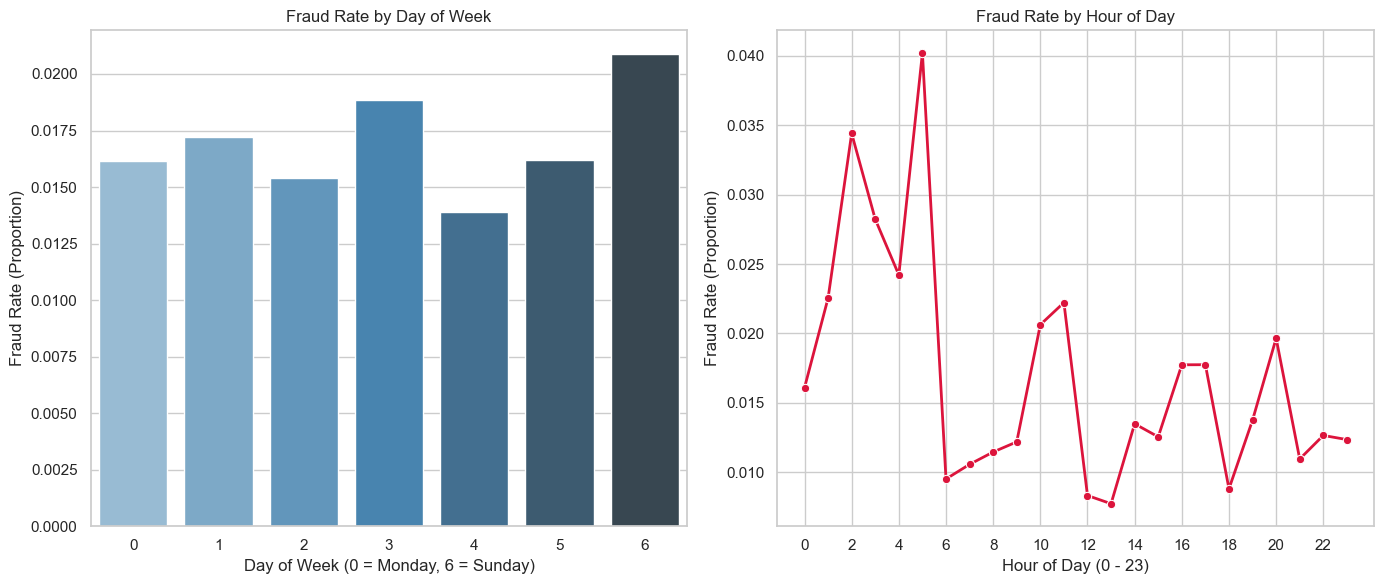

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# 1. Fraud Rate by Day of Week (0 to 6)
plt.subplot(1, 2, 1)
fraud_by_day = df.groupby("day_of_week")["is_fraud"].mean().reset_index()
sns.barplot(
    data=fraud_by_day, x="day_of_week", y="is_fraud", palette="Blues_d"
)
plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day of Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Fraud Rate (Proportion)")

# 2. Fraud Rate by Hour of Day (0 to 23)
plt.subplot(1, 2, 2)
fraud_by_hour = df.groupby("time_of_day_hour")["is_fraud"].mean().reset_index()
sns.lineplot(
    data=fraud_by_hour,
    x="time_of_day_hour",
    y="is_fraud",
    marker="o",
    color="crimson",
    linewidth=2,
)
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day (0 - 23)")
plt.ylabel("Fraud Rate (Proportion)")
plt.xticks(range(0, 24, 2))  # Show every 2 hours for clarity

plt.tight_layout()
plt.show()

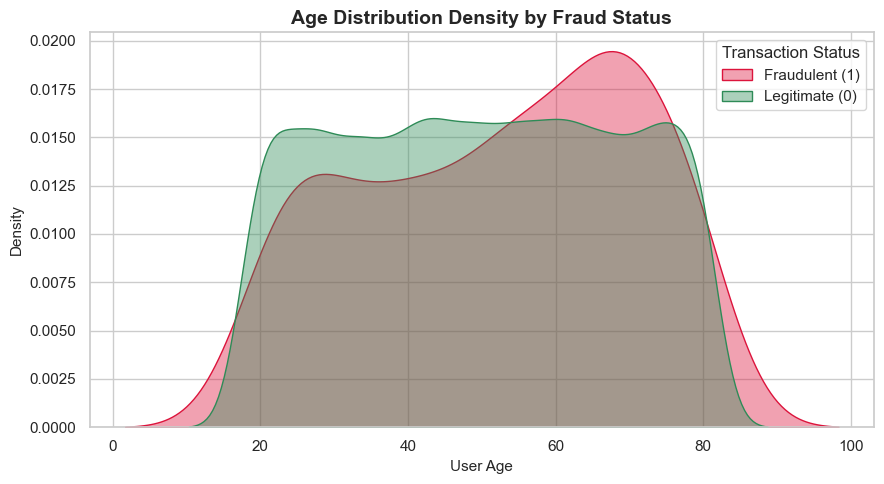

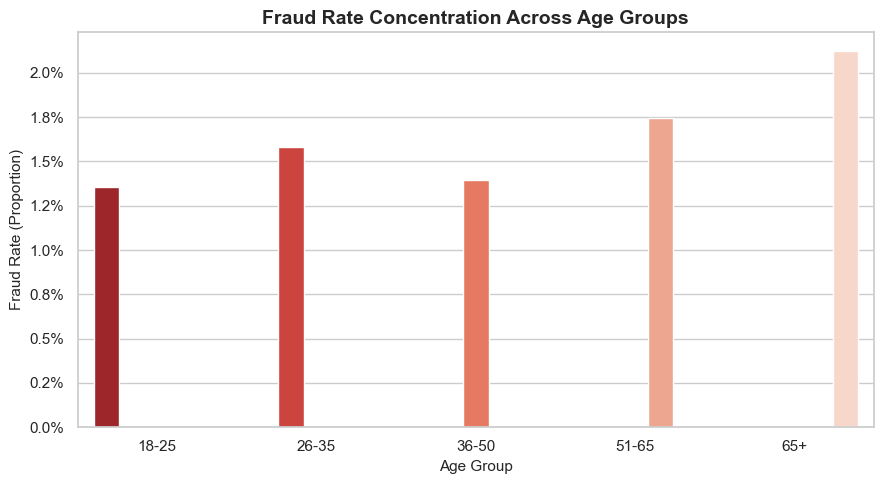

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

if "customer_age" in df.columns:
    # --- 1. DISTRIBUTION PLOT (KDE): Age by Fraud Status ---
    plt.figure(figsize=(9, 5))
    sns.kdeplot(
        data=df,
        x="customer_age",
        hue="is_fraud",
        common_norm=False,
        fill=True,
        palette={0: "seagreen", 1: "crimson"},
        alpha=0.4,
    )

    plt.title(
        "Age Distribution Density by Fraud Status", fontsize=14, fontweight="bold"
    )
    plt.xlabel("User Age", fontsize=11)
    plt.ylabel("Density", fontsize=11)
    plt.legend(title="Transaction Status", labels=[
               "Fraudulent (1)", "Legitimate (0)"])

    plt.tight_layout()
    plt.show()

    # --- 2. BAR CHART: Fraud Rate by Age Cohorts ---
    # Create age bins if they don't already exist
    bins = [18, 25, 35, 50, 65, 100]
    labels = ["18-25", "26-35", "36-50", "51-65", "65+"]
    df["age_group"] = pd.cut(
        df["customer_age"], bins=bins, labels=labels, right=False)

    age_group_fraud = (
        df.groupby("age_group", observed=False)["is_fraud"]
        .mean()
        .reset_index(name="fraud_rate")
    )

    plt.figure(figsize=(9, 5))
    ax = sns.barplot(
        data=age_group_fraud,
        x="age_group",
        y="fraud_rate",
        hue="age_group",
        palette="Reds_r",
        legend=False,
    )

    plt.title(
        "Fraud Rate Concentration Across Age Groups",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Age Group", fontsize=11)
    plt.ylabel("Fraud Rate (Proportion)", fontsize=11)

    # Format y-axis as percentage
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y*100:.1f}%"))

    plt.tight_layout()
    plt.show()
else:
    print("Warning: Column 'age' not found in df. Check your dataset schema.")

In [13]:


# Define the categorical columns to analyze
categorical_cols = [
    "merchant_category",
    "auth_method",
    "channel",
    "device_type",
    "card_type",
]

# --- 1. TABULAR ANALYSIS: Calculate Fraud Rate and Volume ---
for col in categorical_cols:
    print(f"\n--- Fraud Rate Analysis by: {col} ---")

    # Group by category, calculate total transactions, fraud count, and fraud rate (mean of `is_fraud`)
    summary_df = (
        df.groupby(col)
        .agg(
            total_transactions=("is_fraud", "count"),
            fraudulent_transactions=("is_fraud", "sum"),
            fraud_rate=("is_fraud", "mean"),
        )
        .sort_values(by="fraud_rate", ascending=False)
    )

    # Convert fraud rate to a cleaner percentage string for display
    summary_df["fraud_rate_pct"] = (summary_df["fraud_rate"] * 100).round(2).astype(
        str
    ) + "%"
    print(summary_df[["total_transactions",
          "fraudulent_transactions", "fraud_rate_pct"]])


# # --- 2. VISUALIZATION: Fraud Rates Across Categorical Variables ---
# fig, axes = plt.subplots(
#     len(categorical_cols), 1, figsize=(10, 4 * len(categorical_cols))
# )

# for i, col in enumerate(categorical_cols):
#     # Calculate fraud rate per category
#     fraud_rate_df = (
#         df.groupby(col)["is_fraud"]
#         .mean()
#         .reset_index(name="fraud_rate")
#         .sort_values(by="fraud_rate", ascending=False)
#     )

#     # Plot horizontal bar chart
#     sns.barplot(
#         data=fraud_rate_df,
#         x="fraud_rate",
#         y=col,
#         ax=axes[i],
#         palette="Reds_r",
#     )

#     axes[i].set_title(
#         f"Fraud Rate by {col.replace('_', ' ').title()}",
#         fontsize=12,
#         fontweight="bold",
#     )
#     axes[i].set_xlabel("Fraud Rate (Proportion)")
#     axes[i].set_ylabel(col.replace("_", " ").title())

#     # Format x-axis as percentage
#     axes[i].xaxis.set_major_formatter(
#         plt.FuncFormatter(lambda x, _: f"{x*100:.1f}%")
#     )

# plt.suptitle(
#     "Categorical Fraud Risk Breakdown", fontsize=16, fontweight="bold", y=1.01
# )
# plt.show()


--- Fraud Rate Analysis by: merchant_category ---
                   total_transactions  fraudulent_transactions fraud_rate_pct
merchant_category                                                            
Crypto Exchange                   561                       28          4.99%
Gift Cards                        617                       27          4.38%
Gaming                           1036                       38          3.67%
Electronics                      2032                       48          2.36%
Streaming                        1010                       21          2.08%
Utilities                        1330                       25          1.88%
Healthcare                       1237                       16          1.29%
Groceries                        3242                       40          1.23%
Fuel                             1565                       19          1.21%
Restaurants                      2534                       29          1.14%
Travel       

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\775619789.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",


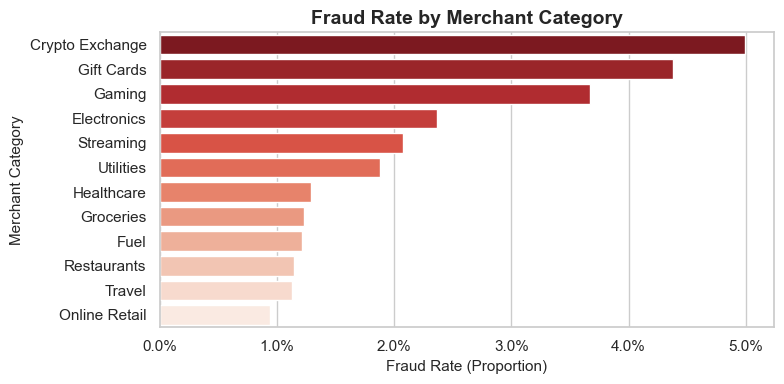

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\775619789.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",


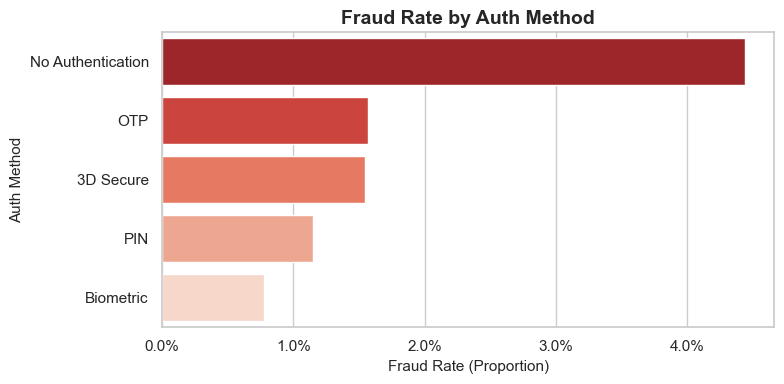

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\775619789.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",


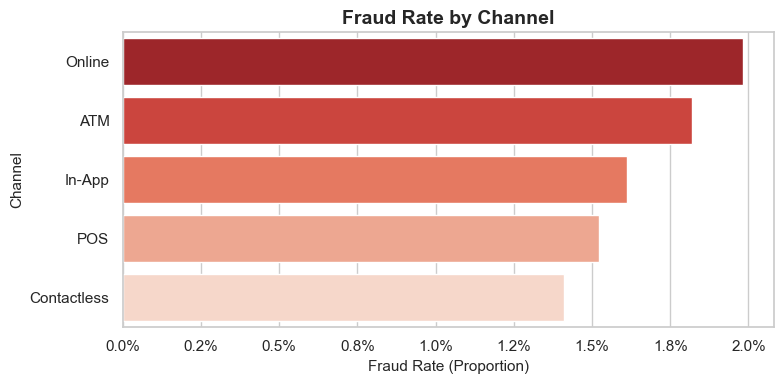

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\775619789.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",


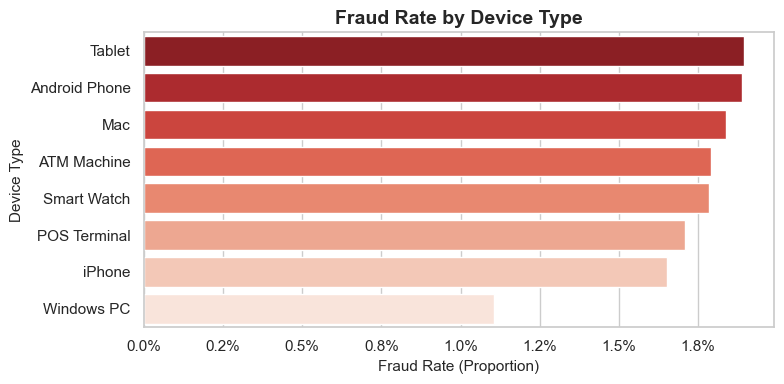

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\775619789.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",


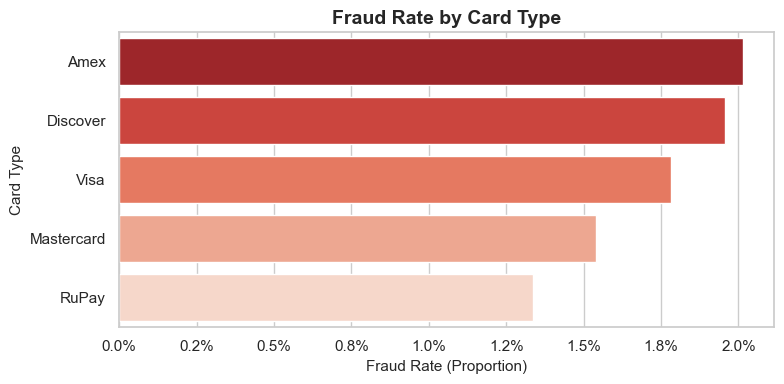

In [14]:

# -----------------------------------------------------------------

# Define the categorical columns you want to analyze
categorical_cols = [
    "merchant_category",
    "auth_method",
    "channel",
    "device_type",
    "card_type",
]

# --- Generate a Separate Chart for Each Categorical Variable ---
for col in categorical_cols:
    # Calculate fraud rate per category
    fraud_rate_df = (
        df.groupby(col)["is_fraud"]
        .mean()
        .reset_index(name="fraud_rate")
        .sort_values(by="fraud_rate", ascending=False)
    )

    # Create a new, independent figure for this specific column
    plt.figure(figsize=(8, 4))

    # Plot horizontal bar chart
    ax = sns.barplot(data=fraud_rate_df, x="fraud_rate",
                     y=col, palette="Reds_r")

    # Styling the chart
    plt.title(
        f"Fraud Rate by {col.replace('_', ' ').title()}",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Fraud Rate (Proportion)", fontsize=11)
    plt.ylabel(col.replace("_", " ").title(), fontsize=11)

    # Format x-axis as a clean percentage (e.g., 5.0%)
    ax.xaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, _: f"{x*100:.1f}%"))

    plt.tight_layout()
    plt.show()

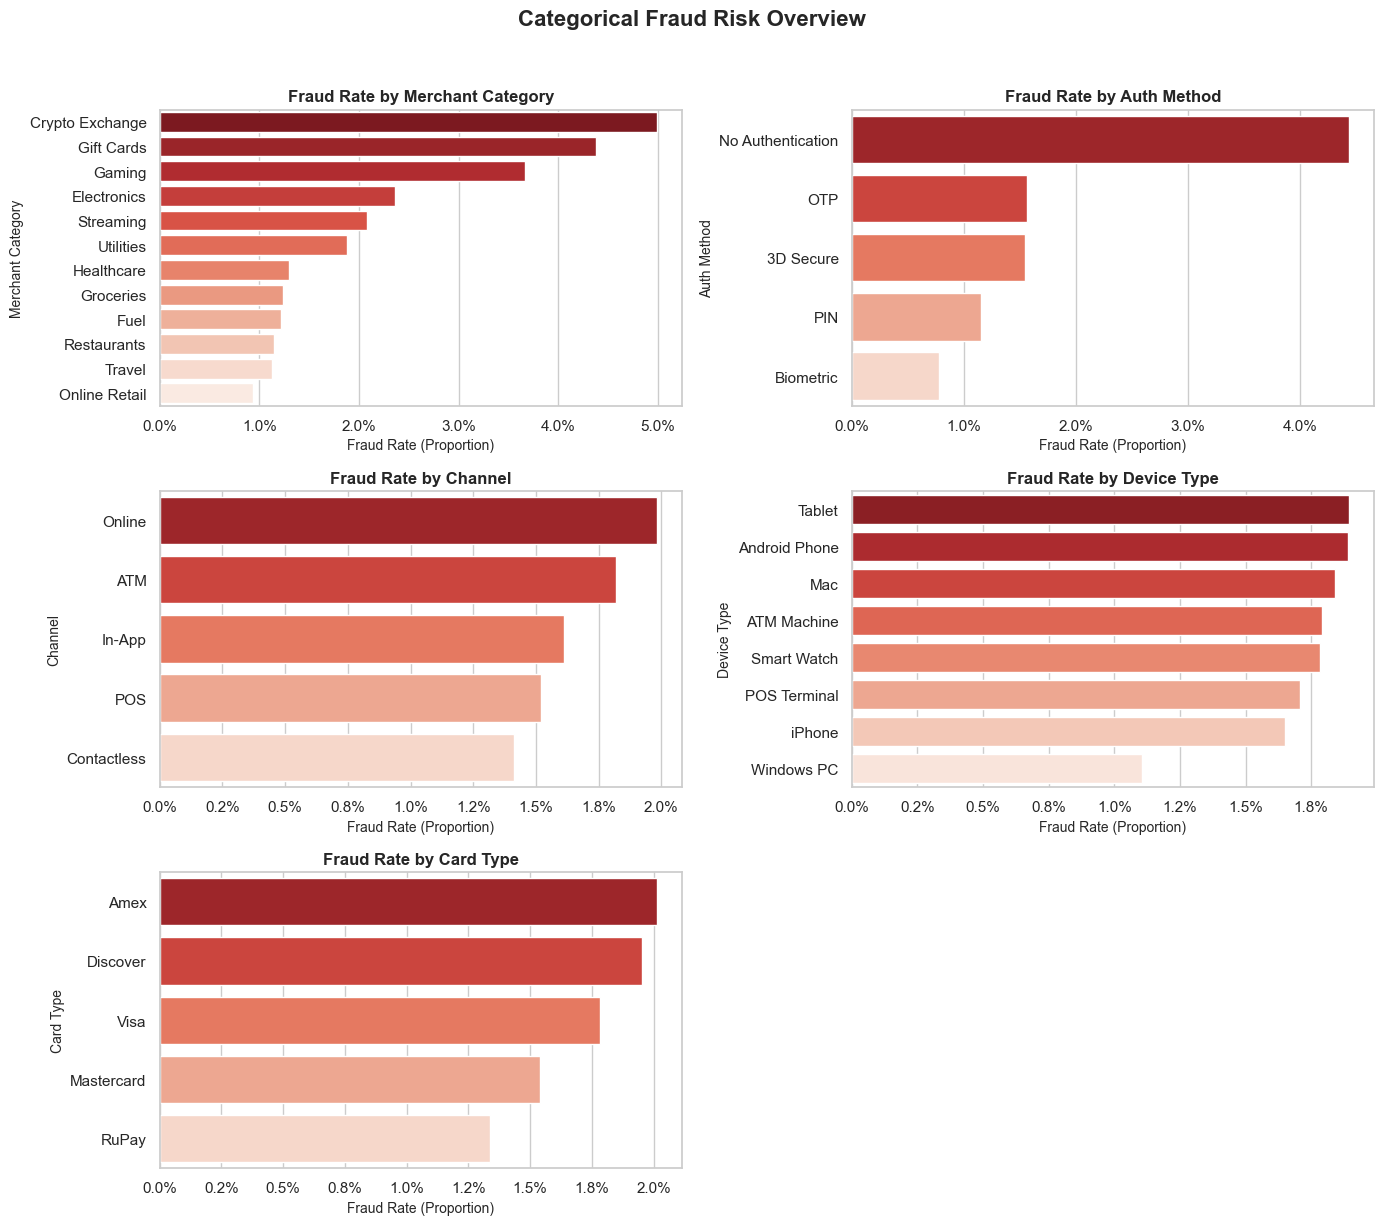

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Define the categorical columns you want to include in the grid
categorical_cols = [
    "merchant_category",
    "auth_method",
    "channel",
    "device_type",
    "card_type",
]

# Create a 3x2 grid of subplots (6 total slots for our 5 categorical columns)
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()  # Flatten the 2D array of axes so we can loop through it easily

for i, col in enumerate(categorical_cols):
    if col in df.columns:
        # Calculate fraud rate per category, sorted highest to lowest
        fraud_rate_df = (
            df.groupby(col)["is_fraud"]
            .mean()
            .reset_index(name="fraud_rate")
            .sort_values(by="fraud_rate", ascending=False)
        )

        # Plot horizontal bar chart on the current subplot axis
        sns.barplot(
            data=fraud_rate_df,
            x="fraud_rate",
            y=col,
            ax=axes[i],
            palette="Reds_r",
            hue=col,
            legend=False,
        )

        # Styling individual subplots
        axes[i].set_title(
            f"Fraud Rate by {col.replace('_', ' ').title()}",
            fontsize=12,
            fontweight="bold",
        )
        axes[i].set_xlabel("Fraud Rate (Proportion)", fontsize=10)
        axes[i].set_ylabel(col.replace("_", " ").title(), fontsize=10)

        # Format x-axis as a clean percentage (e.g., 5.0%)
        axes[i].xaxis.set_major_formatter(
            plt.FuncFormatter(lambda x, _: f"{x*100:.1f}%")
        )

# Remove the 6th empty subplot slot since we only have 5 categorical columns
if len(categorical_cols) < len(axes):
    for j in range(len(categorical_cols), len(axes)):
        fig.delaxes(axes[j])

# Overall title for the grid figure
plt.suptitle(
    "Categorical Fraud Risk Overview", fontsize=16, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

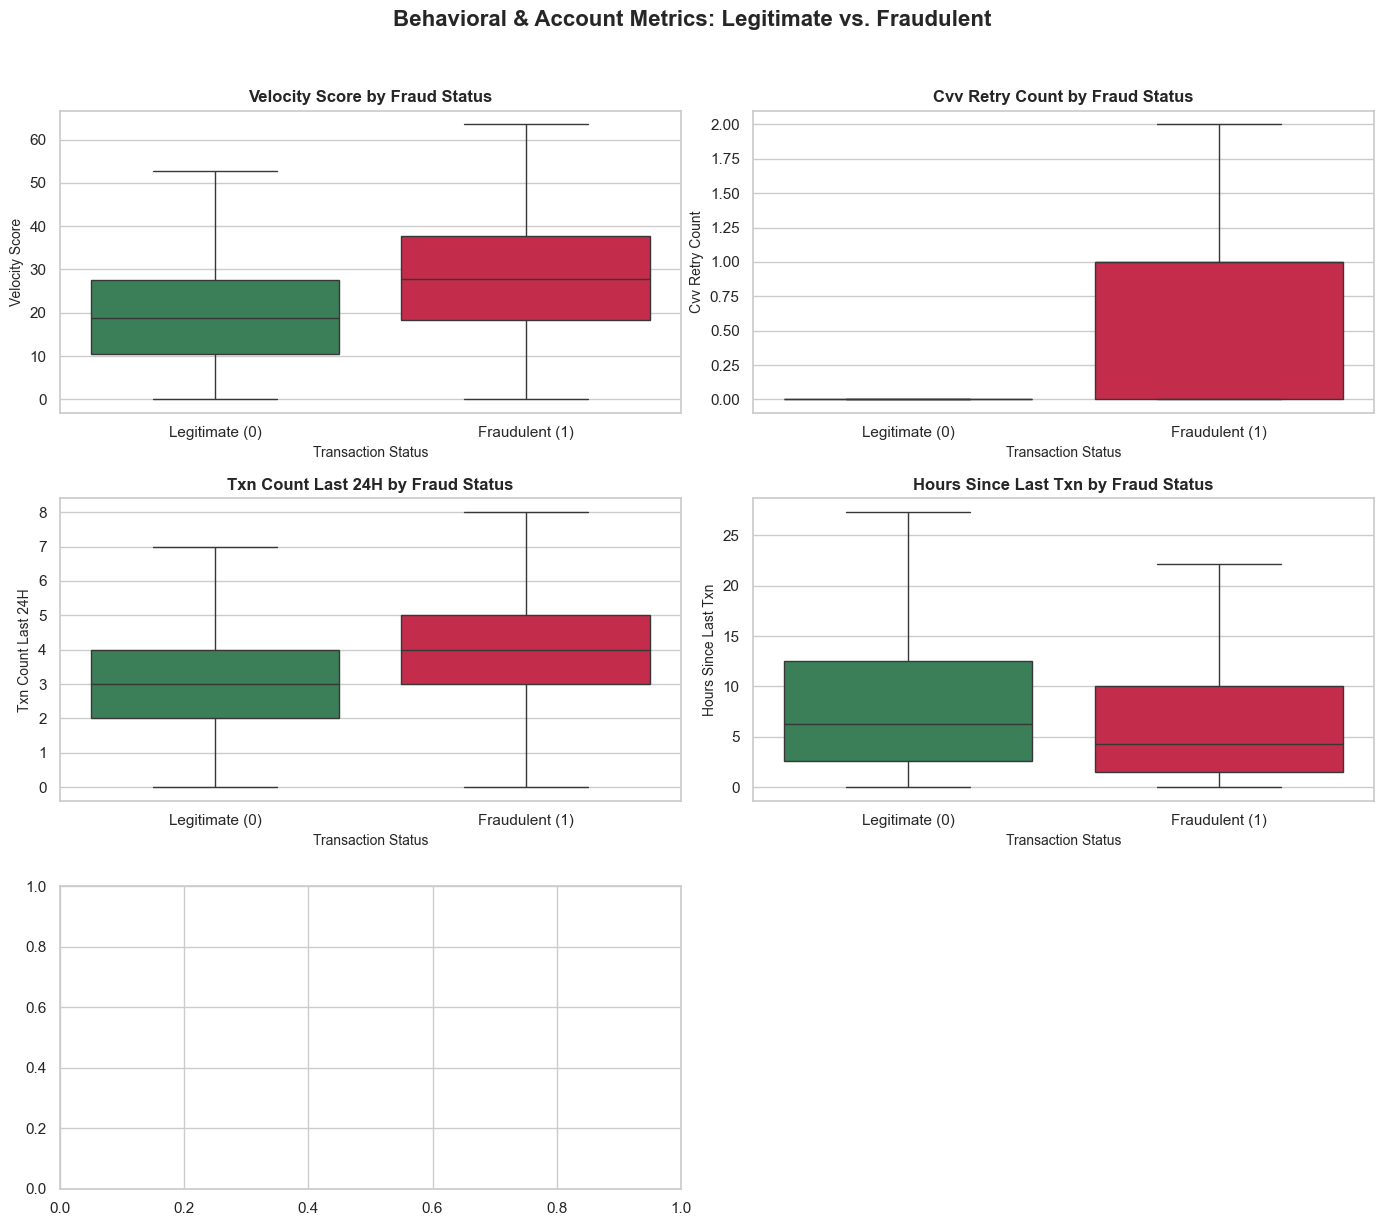

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Define all numerical/velocity features you want in the grid
box_cols = [
    "velocity_score",
    "cvv_retry_count",
    "txn_count_last_24h",
    "hours_since_last_txn",
    "account_balance",
]

# Create a 3x2 grid of subplots (6 total slots for our 5 features)
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()  # Flatten so we can easily loop through them

for i, col in enumerate(box_cols):
    if col in df.columns:
        # Create boxplot on the current subplot axis
        sns.boxplot(
            data=df,
            x="is_fraud",
            y=col,
            ax=axes[i],
            hue="is_fraud",
            palette={0: "seagreen", 1: "crimson"},
            showfliers=False,  # Hides extreme outliers for readability
            legend=False,
        )

        # Styling individual subplots
        axes[i].set_title(
            f"{col.replace('_', ' ').title()} by Fraud Status",
            fontsize=12,
            fontweight="bold",
        )
        axes[i].set_xlabel("Transaction Status", fontsize=10)
        axes[i].set_ylabel(col.replace("_", " ").title(), fontsize=10)

        # Rename x-axis ticks for clarity
        axes[i].set_xticks([0, 1])
        axes[i].set_xticklabels(["Legitimate (0)", "Fraudulent (1)"])

# Remove any unused subplot slots (in this case, the 6th slot)
if len(box_cols) < len(axes):
    for j in range(len(box_cols), len(axes)):
        fig.delaxes(axes[j])

# Overall title for the grid figure
plt.suptitle(
    "Behavioral & Account Metrics: Legitimate vs. Fraudulent",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

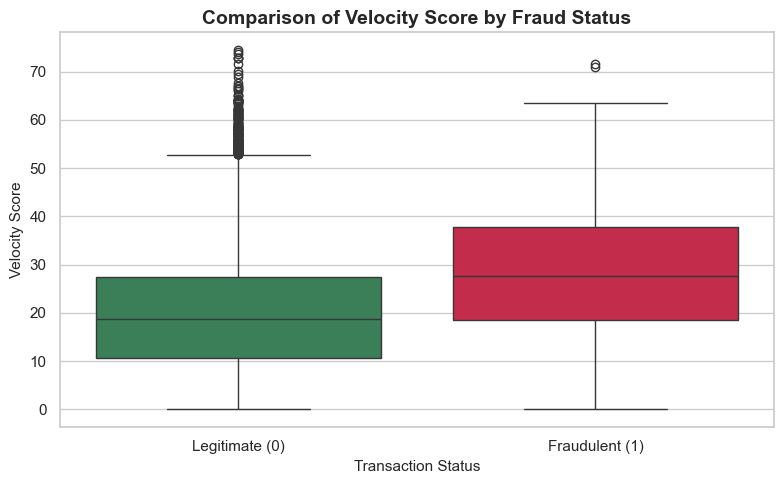

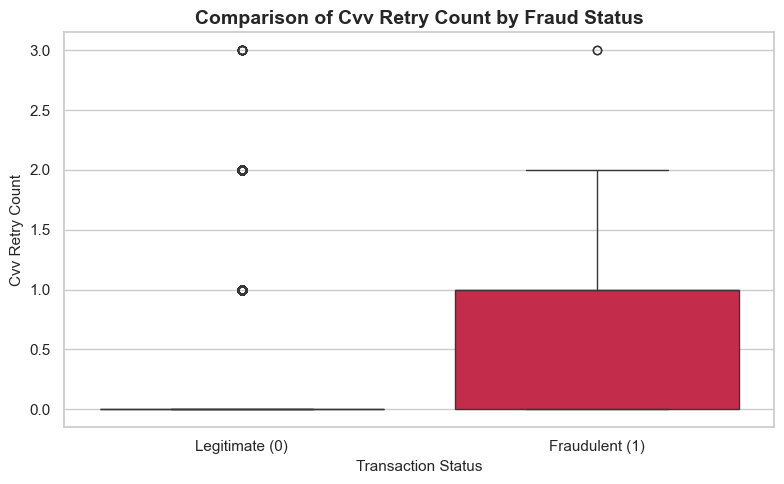

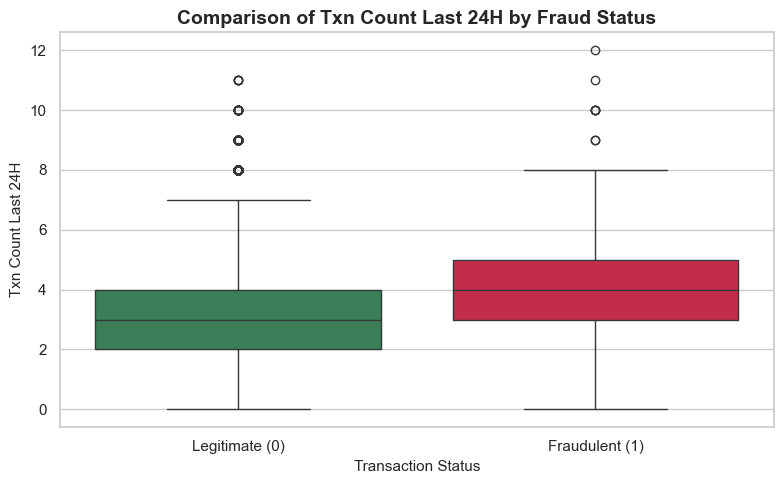

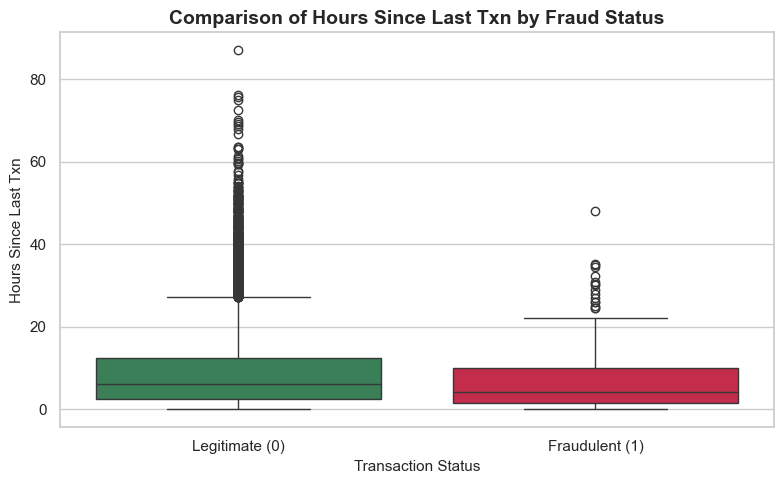

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Define the behavioral and velocity columns
velocity_cols = [
    "velocity_score",
    "cvv_retry_count",
    "txn_count_last_24h",
    "hours_since_last_txn",
]

# Generate a separate chart for each velocity/behavioral metric
for col in velocity_cols:
    plt.figure(figsize=(8, 5))

    # Fixed: Added hue="is_fraud" and legend=False to comply with newer Seaborn rules
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=col,
        hue="is_fraud",
        palette={0: "seagreen", 1: "crimson"},
        # showfliers=False,
        legend=False,
    )

    # Styling the chart
    plt.title(
        f"Comparison of {col.replace('_', ' ').title()} by Fraud Status",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Transaction Status", fontsize=11)
    plt.ylabel(col.replace("_", " ").title(), fontsize=11)

    # Rename x-axis ticks for clarity
    plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

    plt.tight_layout()
    plt.show()


--- Fraud Rate Breakdown by ip_country_mismatch ---
   ip_country_mismatch  total_transactions  fraudulent_count  fraud_rate  \
0                False               18834               248    0.013168   
1                 True                1166                91    0.078045   

  fraud_rate_pct  
0          1.32%  
1           7.8%  

--- Fraud Rate Breakdown by billing_shipping_mismatch ---
   billing_shipping_mismatch  total_transactions  fraudulent_count  \
0                      False               19127               271   
1                       True                 873                68   

   fraud_rate fraud_rate_pct  
0    0.014168          1.42%  
1    0.077892          7.79%  

--- Fraud Rate Breakdown by is_foreign_transaction ---
   is_foreign_transaction  total_transactions  fraudulent_count  fraud_rate  \
0                   False               18760               266    0.014179   
1                    True                1240                73    0.058871   

  fr

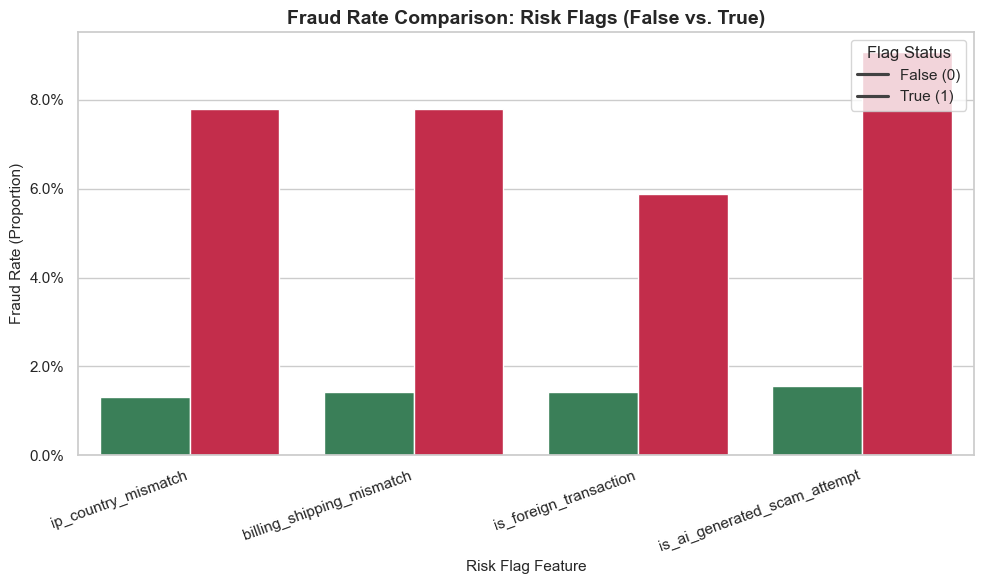

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Define the binary risk flag columns
risk_flags = [
    "ip_country_mismatch",
    "billing_shipping_mismatch",
    "is_foreign_transaction",
    "is_ai_generated_scam_attempt",
]

# --- 1. TABULAR CONDITIONAL PROBABILITY ANALYSIS ---
for col in risk_flags:
    if col in df.columns:
        print(f"\n--- Fraud Rate Breakdown by {col} ---")
        summary = (
            df.groupby(col)["is_fraud"]
            .agg(total_transactions="count", fraudulent_count="sum", fraud_rate="mean")
            .reset_index()
        )
        summary["fraud_rate_pct"] = (summary["fraud_rate"] * 100).round(2).astype(
            str
        ) + "%"
        print(summary)


# --- 2. INTERACTION ANALYSIS (Pivot Table) ---
# Checking how combination of features (e.g., Billing/Shipping Mismatch + Foreign Transaction) impacts fraud rate
if (
    "billing_shipping_mismatch" in df.columns
    and "is_foreign_transaction" in df.columns
):
    print(
        "\n--- Interaction Matrix: Billing/Shipping Mismatch vs. Foreign"
        " Transaction ---"
    )
    interaction_table = pd.pivot_table(
        df,
        values="is_fraud",
        index="billing_shipping_mismatch",
        columns="is_foreign_transaction",
        aggfunc=["count", "mean"],
    )
    print(interaction_table)


# --- 3. VISUALIZATION: Fraud Rates when Flags are True vs. False ---
flag_fraud_rates = []
for col in risk_flags:
    if col in df.columns:
        rates = df.groupby(col)["is_fraud"].mean().reset_index()
        rates["flag_name"] = col
        rates.rename(columns={col: "flag_value",
                     "is_fraud": "fraud_rate"}, inplace=True)
        flag_fraud_rates.append(rates)

if flag_fraud_rates:
    combined_rates = pd.concat(flag_fraud_rates, ignore_index=True)

    plt.figure(figsize=(10, 6))
    ax = sns.barplot(
        data=combined_rates,
        x="flag_name",
        y="fraud_rate",
        hue="flag_value",
        palette={False: "seagreen", True: "crimson"},
    )

    plt.title(
        "Fraud Rate Comparison: Risk Flags (False vs. True)",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Risk Flag Feature", fontsize=11)
    plt.ylabel("Fraud Rate (Proportion)", fontsize=11)
    plt.xticks(rotation=20, ha="right")

    # Format y-axis as percentage
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y*100:.1f}%"))

    plt.legend(title="Flag Status", labels=["False (0)", "True (1)"])
    plt.tight_layout()
    plt.show()

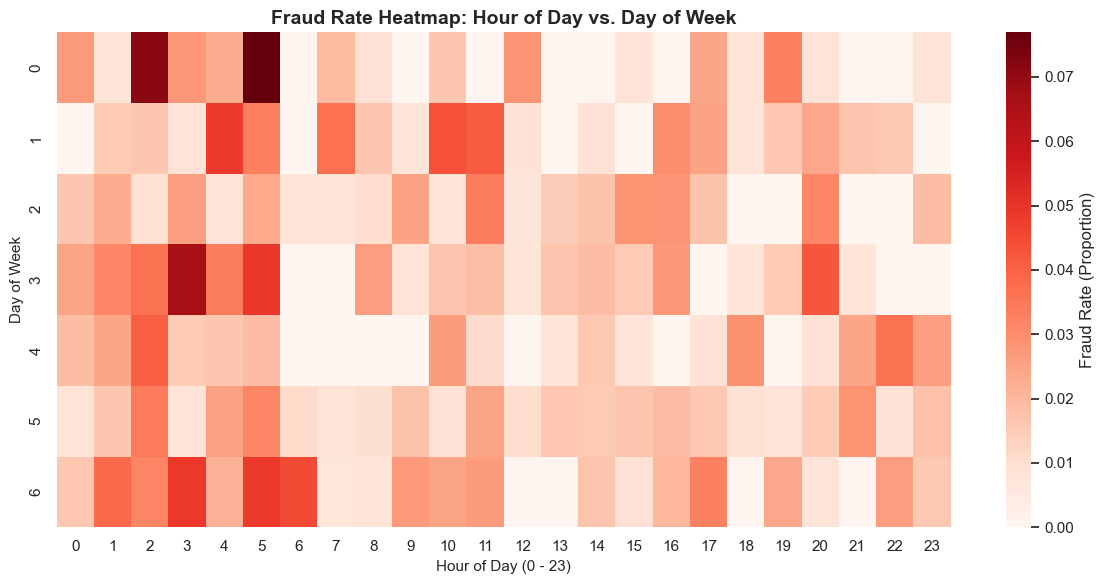

Cyclical time features ('hour_sin', 'hour_cos') successfully created!
   time_of_day_hour      hour_sin      hour_cos
0                18 -1.000000e+00 -1.836970e-16
1                12  1.224647e-16 -1.000000e+00
2                 5  9.659258e-01  2.588190e-01
3                22 -5.000000e-01  8.660254e-01
4                 2  5.000000e-01  8.660254e-01


In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# --- 1. TEMPORAL HEATMAP: Hour of Day vs. Day of Week ---
if "time_of_day_hour" in df.columns and "day_of_week" in df.columns:
    # Create a pivot table calculating the average fraud rate for each combination
    pivot_fraud = df.pivot_table(
        values="is_fraud",
        index="day_of_week",
        columns="time_of_day_hour",
        aggfunc="mean",
    )

    plt.figure(figsize=(12, 6))

    # Generate heatmap using a Red colormap to highlight high-risk time windows
    ax = sns.heatmap(
        pivot_fraud,
        cmap="Reds",
        annot=False,
        cbar_kws={"label": "Fraud Rate (Proportion)"},
    )

    plt.title(
        "Fraud Rate Heatmap: Hour of Day vs. Day of Week",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Hour of Day (0 - 23)", fontsize=11)
    plt.ylabel("Day of Week", fontsize=11)

    plt.tight_layout()
    plt.show()

# --- 2. FEATURE ENGINEERING: Cyclical Sine/Cosine Encoding ---
# This transforms hours (0-23) so that hour 23 and hour 0 sit next to each other mathematically,
# which is crucial for models like Logistic Regression, SVMs, or Neural Networks.
if "time_of_day_hour" in df.columns:
    df["hour_sin"] = np.sin(2 * np.pi * df["time_of_day_hour"] / 24.0)
    df["hour_cos"] = np.cos(2 * np.pi * df["time_of_day_hour"] / 24.0)

    print("Cyclical time features ('hour_sin', 'hour_cos') successfully created!")
    print(df[["time_of_day_hour", "hour_sin", "hour_cos"]].head())


--- Fraud Rate Breakdown by is_new_merchant ---
   is_new_merchant  total_transactions  fraudulent_count  fraud_rate  \
0            False               15399               178    0.011559   
1             True                4601               161    0.034992   

  fraud_rate_pct  
0          1.16%  
1           3.5%  

--- Fraud Rate Breakdown by used_vpn ---
   used_vpn  total_transactions  fraudulent_count  fraud_rate fraud_rate_pct
0     False               18241               262    0.014363          1.44%
1      True                1759                77    0.043775          4.38%


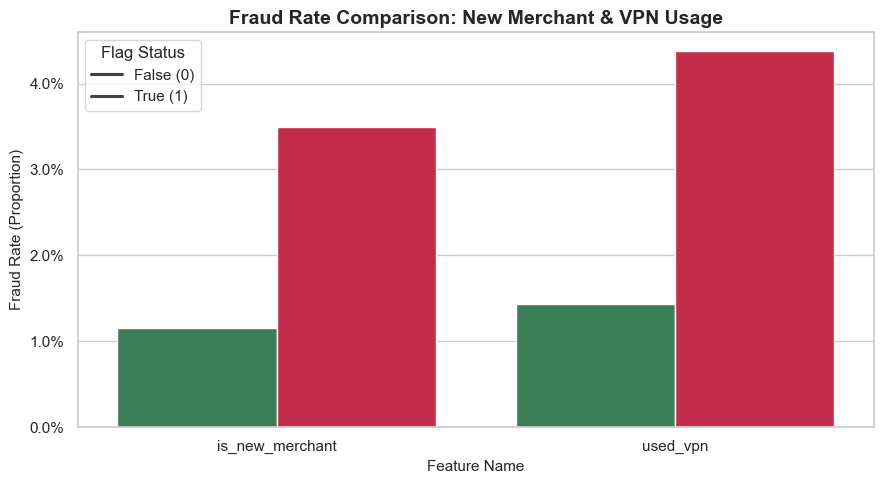

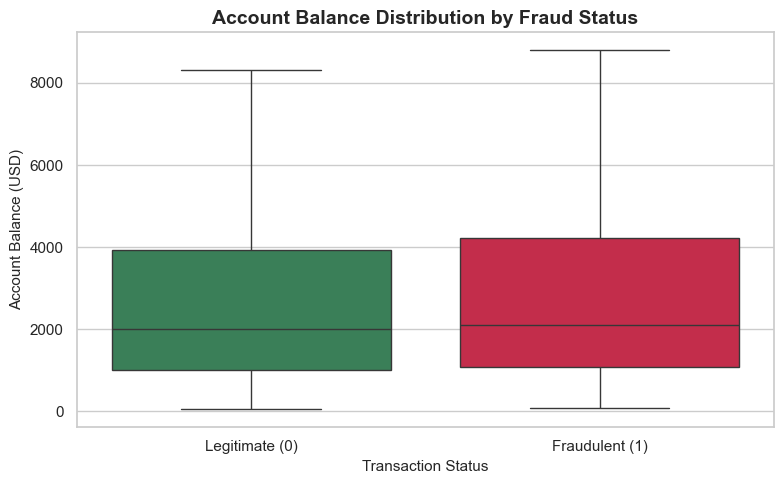

In [20]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# --- 1. TABULAR ANALYSIS FOR BINARY FLAGS ---
binary_cols = ["is_new_merchant", "used_vpn"]

for col in binary_cols:
    if col in df.columns:
        print(f"\n--- Fraud Rate Breakdown by {col} ---")
        summary = (
            df.groupby(col)["is_fraud"]
            .agg(total_transactions="count", fraudulent_count="sum", fraud_rate="mean")
            .reset_index()
        )
        summary["fraud_rate_pct"] = (summary["fraud_rate"] * 100).round(2).astype(
            str
        ) + "%"
        print(summary)


# --- 2. VISUALIZATION: Fraud Rates for Binary Flags ---
# Combine binary flags into a single plotting frame for easy comparison
flag_dfs = []
for col in binary_cols:
    if col in df.columns:
        temp = df.groupby(col)["is_fraud"].mean().reset_index()
        temp["feature"] = col
        temp.rename(
            columns={col: "value", "is_fraud": "fraud_rate"}, inplace=True)
        flag_dfs.append(temp)

if flag_dfs:
    combined_flags = pd.concat(flag_dfs, ignore_index=True)

    plt.figure(figsize=(9, 5))
    ax = sns.barplot(
        data=combined_flags,
        x="feature",
        y="fraud_rate",
        hue="value",
        palette={False: "seagreen", True: "crimson"},
    )

    plt.title(
        "Fraud Rate Comparison: New Merchant & VPN Usage",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Feature Name", fontsize=11)
    plt.ylabel("Fraud Rate (Proportion)", fontsize=11)

    # Format y-axis as percentage
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y*100:.1f}%"))
    plt.legend(title="Flag Status", labels=["False (0)", "True (1)"])
    plt.tight_layout()
    plt.show()


# --- 3. VISUALIZATION: Distribution of Account Balance by Fraud Status ---
if "account_balance_usd" in df.columns:
    plt.figure(figsize=(8, 5))

    # Using a boxplot (showfliers=False hides extreme balance outliers for readability)
    sns.boxplot(
        data=df,
        x="is_fraud",
        y="account_balance_usd",
        hue="is_fraud",
        palette={0: "seagreen", 1: "crimson"},
        showfliers=False,
        legend=False,
    )

    plt.title(
        "Account Balance Distribution by Fraud Status",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Transaction Status", fontsize=11)
    plt.ylabel("Account Balance (USD)", fontsize=11)
    plt.xticks([0, 1], ["Legitimate (0)", "Fraudulent (1)"])

    plt.tight_layout()
    plt.show()

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\3416451029.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_fraud", palette="Set2")
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\3416451029.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="is_fraud", y="velocity_score", palette="Pastel1")
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\3416451029.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


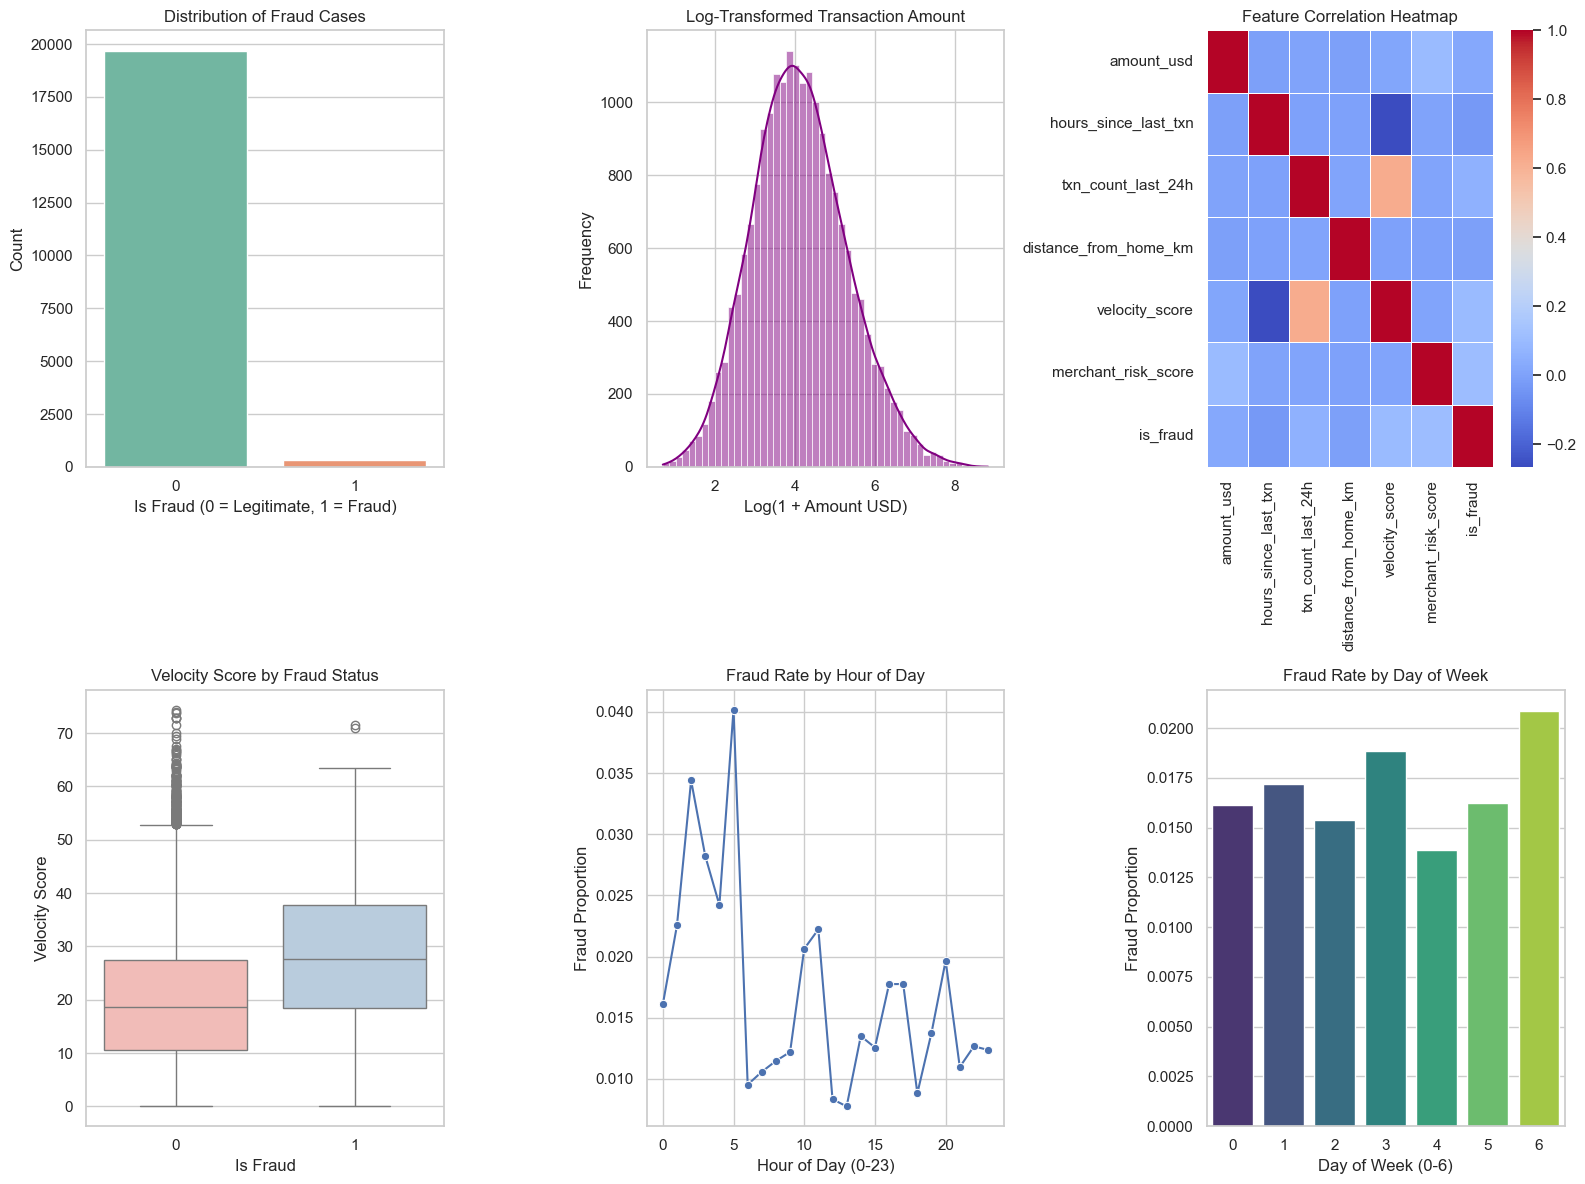

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Class Imbalance Plot
plt.subplot(2, 3, 1)
sns.countplot(data=df, x="is_fraud", palette="Set2")
plt.title("Distribution of Fraud Cases")
plt.xlabel("Is Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Count")

# 2. Transaction Amount Distribution (Log Scale due to heavy skew)
plt.subplot(2, 3, 2)
sns.histplot(
    np.log1p(df["amount_usd"]), kde=True, color="purple", bins=50
)
plt.title("Log-Transformed Transaction Amount")
plt.xlabel("Log(1 + Amount USD)")
plt.ylabel("Frequency")

# 3. Correlation Heatmap
plt.subplot(2, 3, 3)
numeric_cols = [
    "amount_usd",
    "hours_since_last_txn",
    "txn_count_last_24h",
    "distance_from_home_km",
    "velocity_score",
    "merchant_risk_score",
    "is_fraud",
]
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=False, cmap="coolwarm", linewidths=0.5, cbar=True)
plt.title("Feature Correlation Heatmap")

# 4. Velocity Score vs. Fraud Status
plt.subplot(2, 3, 4)
sns.boxplot(data=df, x="is_fraud", y="velocity_score", palette="Pastel1")
plt.title("Velocity Score by Fraud Status")
plt.xlabel("Is Fraud")
plt.ylabel("Velocity Score")

# 5. Fraud Rate by Hour of Day
plt.subplot(2, 3, 5)
fraud_by_hour = df.groupby("time_of_day_hour")["is_fraud"].mean().reset_index()
sns.lineplot(
    data=fraud_by_hour,
    x="time_of_day_hour",
    y="is_fraud",
    marker="o",
    color="b",
)
plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Fraud Proportion")

# 6. Fraud Rate by Day of Week
plt.subplot(2, 3, 6)
fraud_by_day = df.groupby("day_of_week")["is_fraud"].mean().reset_index()
sns.barplot(
    data=fraud_by_day, x="day_of_week", y="is_fraud", palette="viridis"
)
plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day of Week (0-6)")
plt.ylabel("Fraud Proportion")

plt.tight_layout()
plt.show()

C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\717052882.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\717052882.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\717052882.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="is_fraud", y="distance_from_home_km", palette="Set3")
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\717052882.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will

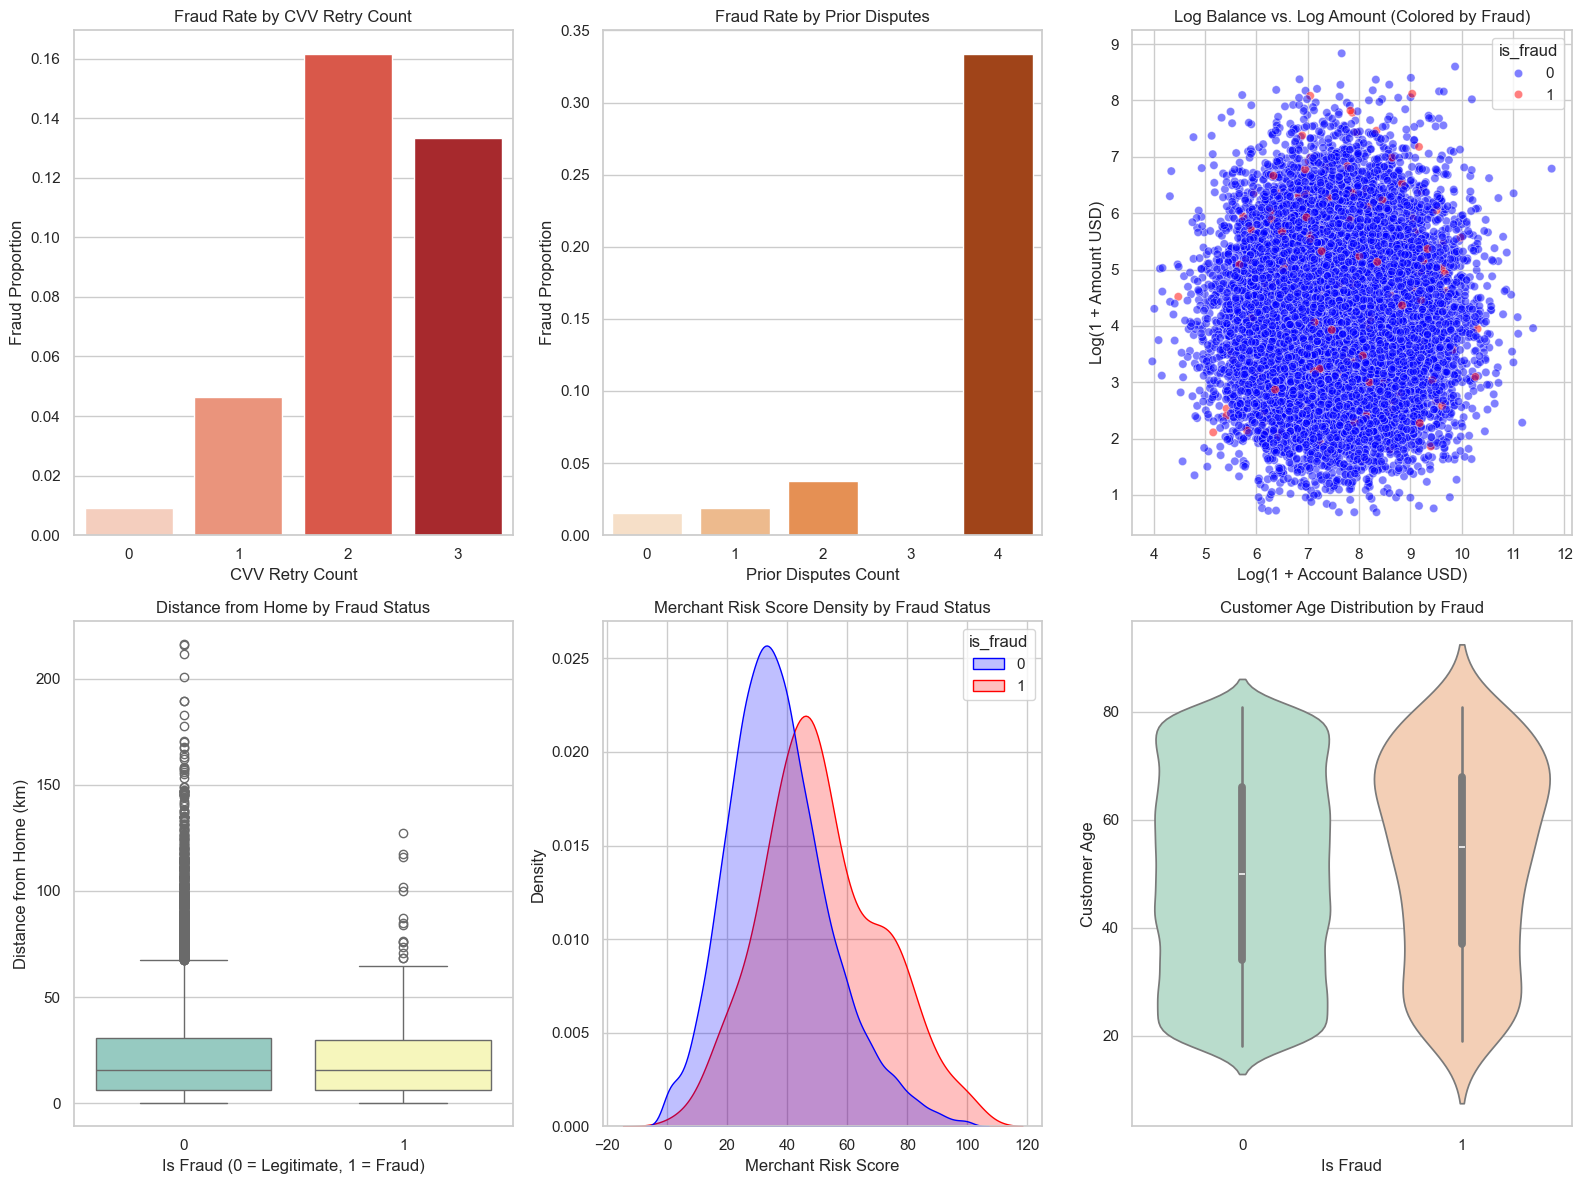

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 12))

# 1. Fraud Rate by CVV Retry Count
plt.subplot(2, 3, 1)
cvv_fraud = df.groupby("cvv_retry_count")["is_fraud"].mean().reset_index()
sns.barplot(
    data=cvv_fraud, x="cvv_retry_count", y="is_fraud", palette="Reds"
)
plt.title("Fraud Rate by CVV Retry Count")
plt.xlabel("CVV Retry Count")
plt.ylabel("Fraud Proportion")

# 2. Fraud Rate by Prior Disputes
plt.subplot(2, 3, 2)
dispute_fraud = df.groupby("prior_disputes")["is_fraud"].mean().reset_index()
sns.barplot(
    data=dispute_fraud, x="prior_disputes", y="is_fraud", palette="Oranges"
)
plt.title("Fraud Rate by Prior Disputes")
plt.xlabel("Prior Disputes Count")
plt.ylabel("Fraud Proportion")

# 3. Account Balance vs Transaction Amount (Log-scaled for clarity)
plt.subplot(2, 3, 3)
sns.scatterplot(
    data=df,
    x=np.log1p(df["account_balance_usd"]),
    y=np.log1p(df["amount_usd"]),
    hue="is_fraud",
    alpha=0.5,
    palette=["blue", "red"],
)
plt.title("Log Balance vs. Log Amount (Colored by Fraud)")
plt.xlabel("Log(1 + Account Balance USD)")
plt.ylabel("Log(1 + Amount USD)")

# 4. Distance from Home by Fraud Status
plt.subplot(2, 3, 4)
sns.boxplot(data=df, x="is_fraud", y="distance_from_home_km", palette="Set3")
plt.title("Distance from Home by Fraud Status")
plt.xlabel("Is Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Distance from Home (km)")

# 5. Merchant Risk Score Distribution by Fraud
plt.subplot(2, 3, 5)
sns.kdeplot(
    data=df,
    x="merchant_risk_score",
    hue="is_fraud",
    common_norm=False,
    fill=True,
    palette=["blue", "red"],
)
plt.title("Merchant Risk Score Density by Fraud Status")
plt.xlabel("Merchant Risk Score")
plt.ylabel("Density")

# 6. Customer Age Distribution by Fraud
plt.subplot(2, 3, 6)
sns.violinplot(data=df, x="is_fraud", y="customer_age", palette="Pastel2")
plt.title("Customer Age Distribution by Fraud")
plt.xlabel("Is Fraud")
plt.ylabel("Customer Age")

plt.tight_layout()
plt.show()

Correlation between AI-generated scam attempt and is_fraud: 0.0789

Fraud Rate Breakdown:
   is_ai_generated_scam_attempt  Total_Transactions  Fraud_Cases  Fraud_Rate
0                         False               19625          305    0.015541
1                          True                 375           34    0.090667


C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\3325715239.py:20: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
C:\Users\Ruby\AppData\Local\Temp\ipykernel_6568\3325715239.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


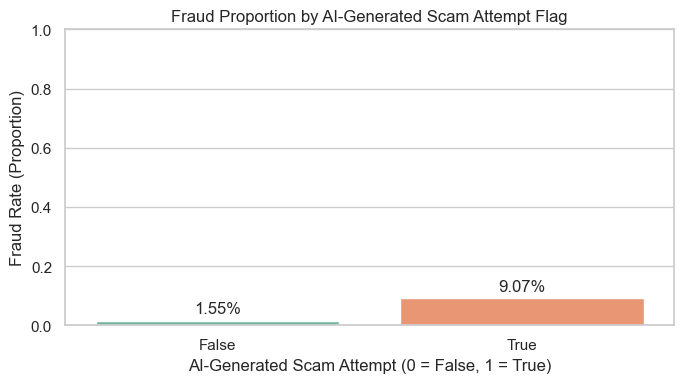

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Compute Pearson / Point-Biserial Correlation Coefficient
correlation = df["is_ai_generated_scam_attempt"].corr(df["is_fraud"])
print(
    f"Correlation between AI-generated scam attempt and is_fraud: {correlation:.4f}")

# 2. Calculate exact fraud rates and counts grouped by the AI flag
fraud_breakdown = (
    df.groupby("is_ai_generated_scam_attempt")["is_fraud"]
    .agg(Total_Transactions="count", Fraud_Cases="sum", Fraud_Rate="mean")
    .reset_index()
)
print("\nFraud Rate Breakdown:")
print(fraud_breakdown)

# 3. Visualization: Fraud Rate Comparison Bar Plot
plt.figure(figsize=(7, 4))
sns.barplot(
    data=df, x="is_ai_generated_scam_attempt", y="is_fraud", palette="Set2", ci=None
)
plt.title("Fraud Proportion by AI-Generated Scam Attempt Flag")
plt.xlabel("AI-Generated Scam Attempt (0 = False, 1 = True)")
plt.ylabel("Fraud Rate (Proportion)")
plt.ylim(0, 1)

# Annotate bars with exact proportions
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().annotate(
        f"{height:.2%}",
        (p.get_x() + p.get_width() / 2., height),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.tight_layout()
plt.show()

In [24]:
correlation = df["is_ai_generated_scam_attempt"].corr(df["is_fraud"])
print(f"Correlation with is_fraud: {correlation:.4f}")

Correlation with is_fraud: 0.0789


In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 10))

# 1. Fraud Rate by Merchant Risk Score Numerical Bins
plt.subplot(2, 2, 1)
df["merchant_risk_bin"] = pd.cut(
    df["merchant_risk_score"],
    bins=[0, 25, 50, 75, 100],
    labels=["0-25", "25-50", "50-75", "75-100"],
)
merchant_risk_fraud = (
    df.groupby("merchant_risk_bin", observed=False)["is_fraud"]
    .mean()
    .reset_index()
)
sns.barplot(
    data=merchant_risk_fraud,
    x="merchant_risk_bin",
    y="is_fraud",
    palette="Blues_d",
)
plt.title("Fraud Rate by Merchant Risk Score Range")
plt.xlabel("Merchant Risk Score Range")
plt.ylabel("Fraud Rate")

# 2. Fraud Rate by Velocity Score Numerical Bins
plt.subplot(2, 2, 2)
df["velocity_bin"] = pd.cut(
    df["velocity_score"],
    bins=[0, 15, 30, 45, 75],
    labels=["0-15", "15-30", "30-45", "45-75"],
)
velocity_fraud = (
    df.groupby("velocity_bin", observed=False)["is_fraud"].mean().reset_index()
)
sns.barplot(
    data=velocity_fraud, x="velocity_bin", y="is_fraud", palette="Oranges_d"
)
plt.title("Fraud Rate by Velocity Score Range")
plt.xlabel("Velocity Score Range")
plt.ylabel("Fraud Rate")

# 3. Fraud Rate by Transaction Amount Numerical Bins (USD)
plt.subplot(2, 2, 3)
df["amount_bin"] = pd.cut(
    df["amount_usd"],
    bins=[0, 50, 200, 500, 7000],
    labels=["$0-$50", "$50-$200", "$200-$500", "$500+"],
)
amount_fraud = (
    df.groupby("amount_bin", observed=False)["is_fraud"].mean().reset_index()
)
sns.barplot(
    data=amount_fraud, x="amount_bin", y="is_fraud", palette="Purples_d"
)
plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Transaction Amount Range ($)")
plt.ylabel("Fraud Rate")

# 4. Fraud Rate by Card Age Numerical Bins (Months)
plt.subplot(2, 2, 4)
df["card_age_bin"] = pd.cut(
    df["card_age_months"],
    bins=[20, 35, 50, 65, 80],
    labels=["20-35m", "35-50m", "50-65m", "65-80m"],
)
card_fraud = (
    df.groupby("card_age_bin", observed=False)["is_fraud"].mean().reset_index()
)
sns.barplot(
    data=card_fraud, x="card

SyntaxError: unterminated string literal (detected at line 76) (304379602.py, line 76)